# Routex: Notebook 04, Model Training

**Project:** Routex, machine-learning-based vehicle fuel consumption prediction
**Author:** Member 2
**Target:** `comb08`, combined fuel economy (MPG)

This notebook trains the **first three regression models**:

| # | Model | Role |
|---|---|---|
| 1 | **Linear Regression** | simple, interpretable baseline |
| 2 | **Decision Tree Regressor** | captures non-linear effects and interactions; easy to visualise |
| 3 | **Random Forest Regressor** | an ensemble of many trees; usually more accurate and more stable than one tree |

Gradient Boosting and XGBoost are planned for a later project stage and are **not** included.

### How the experiment is set up

1. **Data and split** from notebook 02: the same cleaning rules and the same 80/20
   train/test split (`random_state = 42`) for all three models.
2. **One Pipeline per model:** `preprocessing → model`. Imputation, scaling and one-hot
   encoding are therefore fitted **only on training data**, including inside every
   cross-validation fold.
3. **Hyperparameters are chosen with 5-fold cross-validation on the training set**.
   The test set plays no part in any decision.
4. **The test set is used exactly once**, at the end, to report final performance.

Detailed evaluation (residual analysis, errors per vehicle group, feature importance)
follows in the evaluation notebook. This notebook focuses on training the models and
recording their training, cross-validation and test performance.

## 1. Setup

In [1]:
import json
import platform
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src import modeling as mdl
from src import preprocessing as prep

RANDOM_STATE = prep.RANDOM_STATE      # 42, used everywhere randomness is involved
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
for folder in (mdl.MODELS_DIR, mdl.RESULTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

# Chart style, consistent with notebook 03
BLUE, SERIES = "#257de0", ["#257de0", "#f47230", "#00b894"]
TEXT, TEXT_2, GRID = "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.edgecolor": GRID, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "xtick.color": TEXT_2,
    "ytick.color": TEXT_2, "legend.frameon": False,
})

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | "
      f"random_state {RANDOM_STATE} | CV folds {mdl.N_CV_FOLDS}")

Python 3.14.5 | scikit-learn 1.9.1 | random_state 42 | CV folds 5


## 2. Load the data and recreate the train/test split

We rebuild the split from the raw file with the functions from `src/preprocessing.py`.
This keeps the notebook reproducible even on a fresh clone, where the ignored
`data/processed/` files do not exist yet. If notebook 02's saved split *is* present,
we check that both are identical.

In [2]:
raw = prep.load_raw_data()
clean, clean_report = prep.clean_dataset(raw)
X_train, X_test, y_train, y_test = prep.split_features_target(clean)

print(f"Cleaned data: {len(clean):,} vehicles, {len(prep.FEATURES)} features")
print(f"Training set: {len(X_train):,} rows | Test set: {len(X_test):,} rows "
      f"({len(X_test) / len(clean):.0%})")

# Same split as notebook 02?
if (prep.PROCESSED_DIR / "train.csv").exists():
    X_tr_saved, X_te_saved, y_tr_saved, y_te_saved = prep.load_processed_split()
    assert y_tr_saved.tolist() == y_train.tolist() and y_te_saved.tolist() == y_test.tolist()
    pd.testing.assert_frame_equal(X_te_saved.reset_index(drop=True),
                                  X_test.reset_index(drop=True), check_dtype=False)
    print("Split is identical to notebook 02's saved data/processed/ files.")
else:
    print("data/processed/ not found: using the split recreated from the raw data.")

Cleaned data: 42,493 vehicles, 22 features
Training set: 33,994 rows | Test set: 8,499 rows (20%)
Split is identical to notebook 02's saved data/processed/ files.


In [3]:
# Leakage guard: the model only ever sees the 22 approved features.
assert list(X_train.columns) == prep.FEATURES
assert not set(prep.LEAKAGE_COLUMNS) & set(X_train.columns)
assert prep.ID_COLUMN not in X_train.columns and prep.TARGET not in X_train.columns
print("Features:", ", ".join(prep.FEATURES))

Features: year, displ, cylinders, trans_speeds, passenger_volume, luggage_volume, turbo, supercharger, is_cvt, phevBlended, make, VClass, drive, trany, trans_type, trans_dscr, fuelType, fuelType1, fuelType2, atvType, startStop, eng_dscr


### Baseline: always predict the training mean

A model is only useful if it beats this trivial rule. We record its scores for comparison.

In [4]:
baseline_value = y_train.mean()
baseline = {
    "train": mdl.regression_metrics(y_train, np.full(len(y_train), baseline_value)),
    "test": mdl.regression_metrics(y_test, np.full(len(y_test), baseline_value)),
}
print(f"Predict {baseline_value:.2f} MPG for every vehicle:")
pd.DataFrame(baseline).T.round(3)

Predict 20.38 MPG for every vehicle:


,rmse,mae,mape_%,r2
train,5.328,4.015,20.888,0.000
test,5.376,4.030,21.241,-0.001


## 3. Cross-validation setup

`GridSearchCV` tries each hyperparameter combination with **5-fold cross-validation**
on the training set:

- The training set is split into 5 parts (folds). Each combination is trained on 4
  folds and scored on the 5th, five times over.
- Because the whole **Pipeline** is refitted each time, the preprocessing never sees
  the validation fold. There is no leakage inside the CV.
- The folds are shuffled with `random_state = 42`, so the results are reproducible.
- The combination with the **lowest mean RMSE** is selected, and then retrained on the
  full training set (`refit`).

**Metrics:**

| Metric | Meaning | Better |
|---|---|---|
| RMSE | root mean squared error, in MPG. It penalises large errors strongly. | lower |
| MAE | mean absolute error, in MPG, i.e. the typical size of an error | lower |
| MAPE | mean absolute percentage error | lower |
| R² | share of the variation in MPG that the model explains (1 = perfect) | higher |

In [5]:
cv = mdl.make_cv()

def run_search(name, pipeline, param_grid):
    # Grid search with 5-fold CV on the training data; returns the fitted search.
    search = GridSearchCV(pipeline, param_grid, cv=cv, scoring=mdl.CV_SCORING,
                          refit=mdl.REFIT_METRIC, return_train_score=True, n_jobs=1)
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    n = len(search.cv_results_["params"])
    print(f"{name}: {n} combinations x {cv.get_n_splits()} folds = {n * cv.get_n_splits()} fits "
          f"in {elapsed:.0f} s")
    print(f"Best parameters: {search.best_params_}")
    return search, elapsed

searches, search_times = {}, {}

## 4. Model 1: Linear Regression

**Purpose:** Linear Regression predicts MPG as a weighted sum of the inputs:
`comb08 ≈ b0 + b1·x1 + b2·x2 + ...`. It is fast, transparent and the standard
**baseline**. If the more complex models cannot beat it clearly, their extra complexity
is not justified.

**Important settings:**

- **Preprocessing:** scaling *is* needed here, so the numerical features are
  standardised. Categorical features are one-hot encoded.
- **No regularisation** (plain least squares), as the project brief asks for Linear
  Regression.
- **Target transformation (chosen by CV):** the EDA found that `comb08` is right-skewed
  and `log(comb08)` almost symmetric. Engine size also affects MPG roughly in proportion
  (a curved relationship). We therefore let cross-validation decide between
  - fitting `comb08` directly, and
  - fitting `log(comb08)` and converting predictions back with `exp`
    (`TransformedTargetRegressor`). The errors are still measured in MPG.

*Technical note:* the one-hot encoder keeps every category column, so the design matrix
contains redundant columns. scikit-learn's least-squares solver handles this
(it returns the minimum-norm solution), and the predictions are unaffected. Individual
coefficients should not be interpreted, as the EDA already warned (multicollinearity).

In [6]:
lr_grid = {
    "model": [
        LinearRegression(),
        TransformedTargetRegressor(regressor=LinearRegression(), func=np.log, inverse_func=np.exp),
    ],
}
searches["Linear Regression"], search_times["Linear Regression"] = run_search(
    "Linear Regression", mdl.make_pipeline(LinearRegression()), lr_grid)

lr_table = mdl.search_results_table(searches["Linear Regression"])
lr_table["model"] = ["log(comb08) target" if "Transformed" in m else "comb08 target"
                     for m in lr_table["model"].astype(str)]
lr_table.round(4)

Linear Regression: 2 combinations x 5 folds = 10 fits in 7 s
Best parameters: {'model': TransformedTargetRegressor(func=<ufunc 'log'>, inverse_func=<ufunc 'exp'>,
                           regressor=LinearRegression())}


,model,cv_rmse,cv_rmse_std,cv_mae,cv_r2,train_rmse,fit_time_s,rank
0,log(comb08) target,1.8306,0.0146,1.2890,0.8819,1.8112,0.5129,1
1,comb08 target,1.9848,0.0176,1.4195,0.8612,1.9645,0.5362,2


**Result:** cross-validation shows which target scale works better. The selected
version is retrained on the full training set and used from here on.

## 5. Model 2: Decision Tree Regressor

**Purpose:** a decision tree splits the data with a sequence of yes/no questions
(e.g. *displacement ≤ 2.4 L?* → *hybrid?* → *front-wheel drive?*) and predicts the
average MPG of the training vehicles in each final group (leaf). It captures
**non-linear relationships and interactions automatically**, which the EDA found to be
important (curved engine-size effect; hybrids behaving differently).

**Important settings (tuned by CV):**

| Setting | Meaning | Why it matters |
|---|---|---|
| `max_depth` | maximum number of questions from root to leaf | deeper = more detail, but higher risk of memorising the training data |
| `min_samples_leaf` | minimum number of vehicles in each leaf | larger = smoother predictions; prevents leaves built on one or two rare vehicles (EDA: rare makes / engine codes) |
| `random_state = 42` | fixes tie-breaking between equally good splits | reproducibility |

An unrestricted tree would fit the training data almost perfectly and generalise
poorly. The grid below lets CV find the right balance.

Trees do not need scaled inputs (a split threshold works the same either way). The
shared preprocessor still scales the numeric columns, which does no harm.

In [7]:
dt_grid = {
    "model__max_depth": [6, 10, 14, 18, 24, None],
    "model__min_samples_leaf": [1, 3, 5, 10, 20],
}
searches["Decision Tree"], search_times["Decision Tree"] = run_search(
    "Decision Tree", mdl.make_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)), dt_grid)
dt_table = mdl.search_results_table(searches["Decision Tree"])
dt_table.head(10).round(4)

Decision Tree: 30 combinations x 5 folds = 150 fits in 117 s
Best parameters: {'model__max_depth': 24, 'model__min_samples_leaf': 1}


,max_depth,min_samples_leaf,cv_rmse,cv_rmse_std,cv_mae,cv_r2,train_rmse,fit_time_s,rank
0,24.0,1.0,1.0480,0.0312,0.5330,0.9613,0.3440,0.7006,1
1,NaN,1.0,1.0589,0.0380,0.5185,0.9605,0.2514,0.6556,2
2,18.0,1.0,1.0745,0.0362,0.6224,0.9593,0.6088,0.6812,3
3,24.0,3.0,1.0766,0.0497,0.6511,0.9591,0.6228,0.6538,4
4,NaN,3.0,1.0789,0.0476,0.6467,0.9589,0.6016,0.6416,5
5,18.0,3.0,1.1185,0.0518,0.7059,0.9559,0.7437,0.6766,6
6,NaN,5.0,1.1390,0.0377,0.7348,0.9543,0.7950,0.6518,7
7,24.0,5.0,1.1396,0.0363,0.7371,0.9542,0.8025,0.6612,8
8,18.0,5.0,1.1678,0.0374,0.7705,0.9519,0.8678,0.6614,9
9,14.0,1.0,1.1976,0.0332,0.7908,0.9495,0.9270,0.6990,10


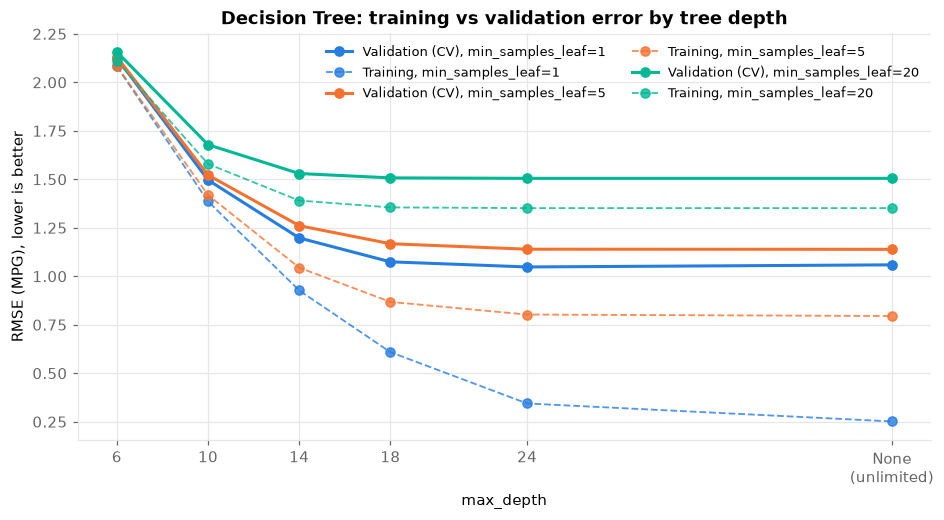

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
plot_df = dt_table.copy()
plot_df["depth"] = plot_df["max_depth"].fillna(40).astype(int)  # None plotted as 40 ("unlimited")
for colour, leaf in zip(SERIES, [1, 5, 20]):
    d = plot_df[plot_df["min_samples_leaf"] == leaf].sort_values("depth")
    ax.plot(d["depth"], d["cv_rmse"], marker="o", color=colour, linewidth=2,
            label=f"Validation (CV), min_samples_leaf={leaf}")
    ax.plot(d["depth"], d["train_rmse"], marker="o", color=colour, linewidth=1.2,
            linestyle="--", alpha=0.8, label=f"Training, min_samples_leaf={leaf}")
ax.set_xticks(sorted(plot_df["depth"].unique()),
              [str(d) if d != 40 else "None\n(unlimited)" for d in sorted(plot_df["depth"].unique())])
ax.set_title("Decision Tree: training vs validation error by tree depth")
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE (MPG), lower is better")
ax.legend(ncol=2, fontsize=8.5, loc="upper right")
fig.savefig(FIGURES_DIR / "04_decision_tree_depth.png")
plt.show()

**Reading the chart:** the dashed lines (training error) keep falling as the tree gets
deeper. Deep trees with tiny leaves almost memorise the training data. The solid lines
(validation error) stop improving after a certain depth. The gap between the two is
**overfitting**. Larger `min_samples_leaf` values narrow the gap.

## 6. Model 3: Random Forest Regressor

**Purpose:** a random forest trains **many decision trees** and averages their
predictions. Each tree:

- is trained on a **bootstrap sample** (a random sample of the training rows, drawn
  with replacement), and
- considers only a **random subset of the features** at each split.

Because the trees make different mistakes, averaging them cancels out much of the
noise. A forest keeps the single tree's ability to model non-linear effects and
interactions, but is far less prone to overfitting.

**Important settings:**

| Setting | Value / grid | Why |
|---|---|---|
| `n_estimators` | 300 trees | more trees = more stable average; 300 is well past the point where results stop changing noticeably |
| `max_features` | tuned: 0.33, 0.6, 1.0 (share of features per split) | smaller = more diverse trees; 1.0 = every split sees all features |
| `min_samples_leaf` | tuned: 1, 2, 4 | as for the single tree: controls how detailed each tree is |
| `max_depth` | `None` | individual trees may grow deep; averaging controls overfitting |
| `bootstrap` | `True` (default) | each tree sees a different random sample |
| `random_state` | 42 | reproducible bootstrap samples and feature choices |
| `n_jobs` | −1 | trains trees in parallel on all CPU cores |

In [9]:
rf_grid = {
    "model__max_features": [0.33, 0.6, 1.0],
    "model__min_samples_leaf": [1, 2, 4],
}
rf_model = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
searches["Random Forest"], search_times["Random Forest"] = run_search(
    "Random Forest", mdl.make_pipeline(rf_model), rf_grid)
rf_table = mdl.search_results_table(searches["Random Forest"])
rf_table.round(4)

Random Forest: 9 combinations x 5 folds = 45 fits in 435 s
Best parameters: {'model__max_features': 0.6, 'model__min_samples_leaf': 1}


,max_features,min_samples_leaf,cv_rmse,cv_rmse_std,cv_mae,cv_r2,train_rmse,fit_time_s,rank
0,0.60,1.0,0.8144,0.0209,0.5233,0.9766,0.3650,8.9120,1
1,0.33,1.0,0.8198,0.0178,0.5349,0.9763,0.3672,5.4115,2
2,1.00,1.0,0.8322,0.0271,0.5248,0.9756,0.3702,13.4650,3
3,0.60,2.0,0.8616,0.0252,0.5751,0.9738,0.5251,8.5029,4
4,1.00,2.0,0.8756,0.0307,0.5713,0.9730,0.5107,12.8272,5
5,0.33,2.0,0.8847,0.0223,0.6020,0.9724,0.5739,5.3765,6
6,0.60,4.0,0.9728,0.0267,0.6645,0.9667,0.7366,8.0801,7
7,1.00,4.0,0.9790,0.0287,0.6574,0.9662,0.7179,12.2779,8
8,0.33,4.0,1.0148,0.0237,0.7015,0.9637,0.8012,5.3890,9


## 7. Final models: training, cross-validation and test performance

Each `best_estimator_` is the complete pipeline (preprocessing + model) with the
selected settings, **retrained on the whole training set**. We now:

1. score it on the training set (how well it fits the data it learned from),
2. report its cross-validation score (an estimate of performance on unseen data), and
3. **predict the test set for the first and only time** and score it.

In [10]:
final_models = {name: s.best_estimator_ for name, s in searches.items()}
test_predictions = {}
rows = []
for name, pipe in final_models.items():
    s = searches[name]
    train_pred = pipe.predict(X_train)
    start = time.perf_counter()
    test_pred = pipe.predict(X_test)
    predict_time = time.perf_counter() - start
    test_predictions[name] = test_pred

    train_m = mdl.regression_metrics(y_train, train_pred)
    test_m = mdl.regression_metrics(y_test, test_pred)
    cv_m = mdl.cv_summary(s.cv_results_, s.best_index_)
    rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_m.items()},
        **cv_m,
        **{f"test_{k}": v for k, v in test_m.items()},
        "search_time_s": search_times[name],
        "refit_time_s": s.refit_time_,
        "test_predict_time_s": predict_time,
    })

rows.append({"model": "Baseline (training mean)",
             **{f"train_{k}": v for k, v in baseline["train"].items()},
             **{f"test_{k}": v for k, v in baseline["test"].items()}})
metrics = pd.DataFrame(rows).set_index("model")

overview_cols = ["train_rmse", "cv_rmse", "cv_rmse_std", "test_rmse",
                 "train_mae", "cv_mae", "test_mae", "test_mape_%", "train_r2", "cv_r2", "test_r2"]
metrics[overview_cols].round(3)

,train_rmse,cv_rmse,cv_rmse_std,test_rmse,train_mae,cv_mae,test_mae,test_mape_%,train_r2,cv_r2,test_r2
model,,,,,,,,,,,
Linear Regression,1.807,1.831,0.015,1.823,1.274,1.289,1.283,6.304,0.885,0.882,0.885
Decision Tree,0.370,1.048,0.031,0.939,0.140,0.533,0.473,2.419,0.995,0.961,0.969
Random Forest,0.361,0.814,0.021,0.752,0.208,0.523,0.476,2.457,0.995,0.977,0.980
Baseline (training mean),5.328,NaN,NaN,5.376,4.015,NaN,4.030,21.241,0.000,NaN,-0.001


In [11]:
gap = pd.DataFrame({
    "train_rmse": metrics["train_rmse"],
    "test_rmse": metrics["test_rmse"],
    "gap (test - train)": metrics["test_rmse"] - metrics["train_rmse"],
    "test vs CV difference": metrics["test_rmse"] - metrics["cv_rmse"],
}).drop(index="Baseline (training mean)")
gap.round(3)

,train_rmse,test_rmse,gap (test - train),test vs CV difference
model,,,,
Linear Regression,1.807,1.823,0.016,-0.007
Decision Tree,0.370,0.939,0.569,-0.109
Random Forest,0.361,0.752,0.391,-0.062


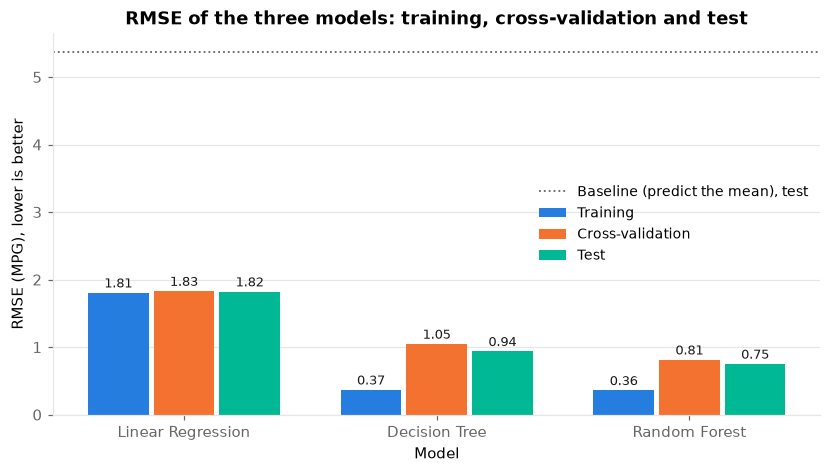

In [12]:
model_names = list(final_models)
x = np.arange(len(model_names))
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (col, label) in enumerate([("train_rmse", "Training"), ("cv_rmse", "Cross-validation"),
                                  ("test_rmse", "Test")]):
    vals = metrics.loc[model_names, col]
    bars = ax.bar(x + (i - 1) * 0.26, vals, width=0.24, color=SERIES[i], label=label)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.2f}", ha="center",
                va="bottom", fontsize=8.5, color=TEXT)
ax.axhline(metrics.loc["Baseline (training mean)", "test_rmse"], color=TEXT_2, linestyle=":",
           linewidth=1.2, label="Baseline (predict the mean), test")
ax.set_xticks(x, model_names)
ax.set_title("RMSE of the three models: training, cross-validation and test")
ax.set_xlabel("Model")
ax.set_ylabel("RMSE (MPG), lower is better")
ax.legend(loc="center right", fontsize=9)
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES_DIR / "04_model_rmse_comparison.png")
plt.show()

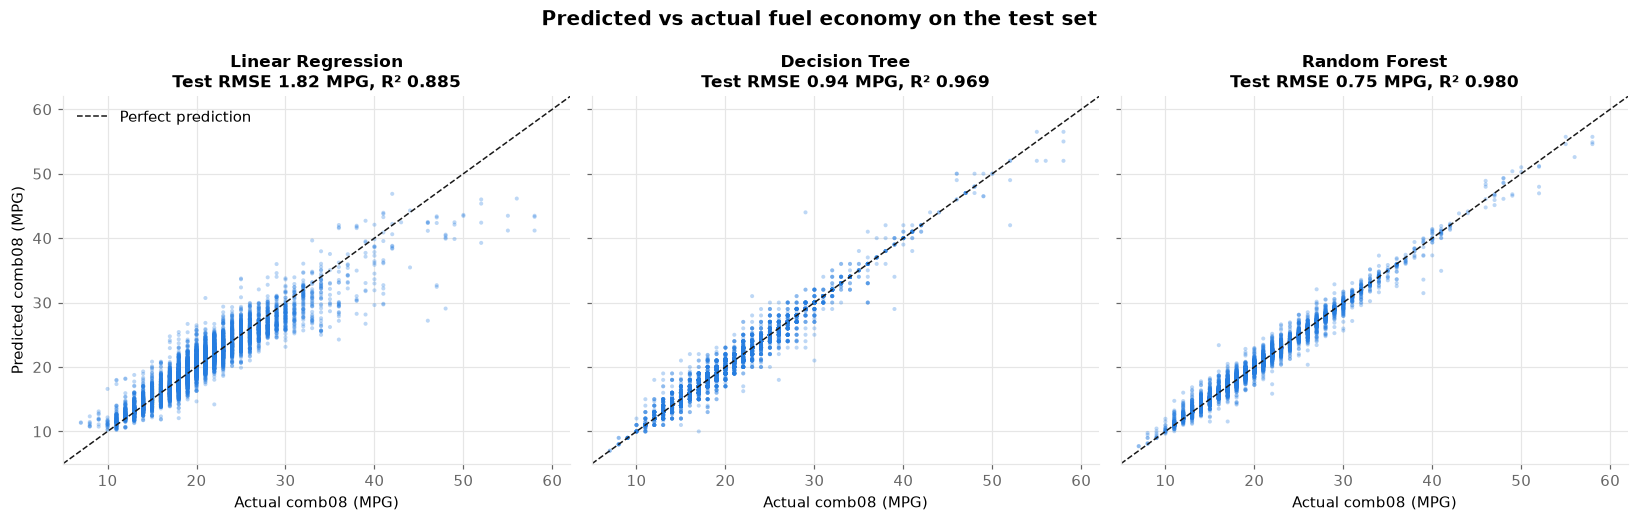

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
lims = (5, 62)
for ax, name in zip(axes, model_names):
    pred = test_predictions[name]
    ax.scatter(y_test, pred, s=7, alpha=0.3, color=BLUE, edgecolors="none")
    ax.plot(lims, lims, color=TEXT, linewidth=1, linestyle="--", label="Perfect prediction")
    m = metrics.loc[name]
    ax.set_title(f"{name}\nTest RMSE {m.test_rmse:.2f} MPG, R² {m.test_r2:.3f}", fontsize=11)
    ax.set_xlabel("Actual comb08 (MPG)")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
axes[0].set_ylabel("Predicted comb08 (MPG)")
axes[0].legend(loc="upper left")
fig.suptitle("Predicted vs actual fuel economy on the test set", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_predicted_vs_actual.png")
plt.show()

Points on the dashed diagonal are perfect predictions. Points above it are
over-predictions, and points below it are under-predictions.

## 8. Save the trained models and the experiment results

| Output | Location | In Git? |
|---|---|---|
| Trained pipelines (preprocessing + model) | `models/*.joblib` | No: `models/` is ignored; the files are recreated by running this notebook |
| Metrics of all models | `results/model_metrics.csv` | Yes |
| All CV results per model | `results/cv_results_*.csv` | Yes |
| Test-set predictions (+ a few descriptive columns for the evaluation notebook) | `results/test_predictions.csv` | Yes |
| Settings, versions and timings | `results/training_summary.json` | Yes |

Each saved model is the **complete pipeline**, so it can be applied directly to raw
feature columns: `joblib.load(path).predict(X)`.

In [14]:
file_names = {"Linear Regression": "linear_regression", "Decision Tree": "decision_tree",
              "Random Forest": "random_forest"}

saved = []
for name, pipe in final_models.items():
    path = mdl.MODELS_DIR / f"{file_names[name]}.joblib"
    joblib.dump(pipe, path, compress=3)
    saved.append(path)

metrics.to_csv(mdl.RESULTS_DIR / "model_metrics.csv", float_format="%.5f")
for name, table in {"linear_regression": lr_table, "decision_tree": dt_table,
                    "random_forest": rf_table}.items():
    path = mdl.RESULTS_DIR / f"cv_results_{name}.csv"
    table.to_csv(path, index=False, float_format="%.5f")
    saved.append(path)

predictions = X_test[["year", "make", "VClass", "atvType", "displ", "cylinders"]].copy()
predictions.insert(0, "test_row", np.arange(len(X_test)))
predictions["actual_comb08"] = y_test.values
for name, pred in test_predictions.items():
    predictions[f"pred_{file_names[name]}"] = np.round(pred, 4)
predictions.to_csv(mdl.RESULTS_DIR / "test_predictions.csv", index=False)

summary = {
    "target": prep.TARGET,
    "random_state": RANDOM_STATE,
    "split": {"test_size": prep.TEST_SIZE, "train_rows": len(X_train), "test_rows": len(X_test)},
    "cross_validation": {"folds": mdl.N_CV_FOLDS, "shuffle": True, "selection_metric": "RMSE"},
    "features": prep.FEATURES,
    "models": {
        name: {
            "file": f"models/{file_names[name]}.joblib",
            "estimator": repr(final_models[name].named_steps["model"]),
            "best_params": {k: (v if isinstance(v, (int, float, str, type(None))) else repr(v))
                            for k, v in searches[name].best_params_.items()},
            "search_time_s": round(search_times[name], 1),
            "train_rmse": round(metrics.loc[name, "train_rmse"], 4),
            "cv_rmse": round(metrics.loc[name, "cv_rmse"], 4),
            "test_rmse": round(metrics.loc[name, "test_rmse"], 4),
            "test_mae": round(metrics.loc[name, "test_mae"], 4),
            "test_r2": round(metrics.loc[name, "test_r2"], 4),
        } for name in final_models
    },
    "baseline_test_rmse": round(baseline["test"]["rmse"], 4),
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
}
with open(mdl.RESULTS_DIR / "training_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
saved += [mdl.RESULTS_DIR / "model_metrics.csv", mdl.RESULTS_DIR / "test_predictions.csv",
          mdl.RESULTS_DIR / "training_summary.json"]

for path in saved:
    print(f"Saved {path.relative_to(PROJECT_ROOT)}  ({path.stat().st_size / 1024:,.0f} KB)")

Saved models\linear_regression.joblib  (14 KB)
Saved models\decision_tree.joblib  (266 KB)
Saved models\random_forest.joblib  (77,222 KB)
Saved results\cv_results_linear_regression.csv  (0 KB)
Saved results\cv_results_decision_tree.csv  (2 KB)
Saved results\cv_results_random_forest.csv  (1 KB)
Saved results\model_metrics.csv  (1 KB)
Saved results\test_predictions.csv  (676 KB)
Saved results\training_summary.json  (2 KB)


In [15]:
# Reload check: the saved pipelines reproduce the test predictions exactly.
for name in final_models:
    reloaded = joblib.load(mdl.MODELS_DIR / f"{file_names[name]}.joblib")
    assert np.allclose(reloaded.predict(X_test), test_predictions[name])
print("All saved models reload and reproduce their test predictions.")

All saved models reload and reproduce their test predictions.


## 9. Summary

In [16]:
summary_table = metrics.loc[model_names + ["Baseline (training mean)"],
                            ["train_rmse", "cv_rmse", "test_rmse", "test_mae", "test_r2"]].round(3)
summary_table["selected settings"] = [
    ", ".join(f"{k.replace('model__', '')}={v if not hasattr(v, 'fit') else type(v).__name__}"
              for k, v in searches[n].best_params_.items()) for n in model_names] + ["-"]
summary_table

,train_rmse,cv_rmse,test_rmse,test_mae,test_r2,selected settings
model,,,,,,
Linear Regression,1.807,1.831,1.823,1.283,0.885,model=TransformedTargetRegressor
Decision Tree,0.370,1.048,0.939,0.473,0.969,"max_depth=24, min_samples_leaf=1"
Random Forest,0.361,0.814,0.752,0.476,0.980,"max_features=0.6, min_samples_leaf=1"
Baseline (training mean),5.328,NaN,5.376,4.030,-0.001,-


### Models trained

| Model | Selected settings (5-fold CV) | Train RMSE | CV RMSE | **Test RMSE** | Test MAE | Test R² |
|---|---|---|---|---|---|---|
| Linear Regression | target modelled as `log(comb08)` | 1.81 | 1.83 | **1.82** | 1.28 | 0.885 |
| Decision Tree | `max_depth=24`, `min_samples_leaf=1` | 0.37 | 1.05 | **0.94** | 0.47 | 0.969 |
| Random Forest | 300 trees, `max_features=0.6`, `min_samples_leaf=1` | 0.36 | 0.81 | **0.75** | 0.48 | 0.980 |
| Baseline (predict the mean) | - | 5.33 | - | 5.38 | 4.03 | 0.00 |

### Key observations

1. **All three models are far better than the baseline.** Even Linear Regression
   reduces the typical error (RMSE) from 5.4 to 1.8 MPG.
2. **Random Forest is the most accurate model** (test RMSE 0.75 MPG, R² 0.98, a typical
   error of about 0.5 MPG). The tree-based models are clearly better than Linear
   Regression, as the EDA predicted: the relationships are curved and involve
   interactions (e.g. hybrid × engine size), which a straight-line model cannot represent.
3. **The log target helped Linear Regression**, as suggested by the EDA (CV RMSE 1.83
   vs 1.98 on the raw scale). Its predictions still flatten out above about 40 MPG
   (the hybrids, see the scatter plot), where the linear model underestimates.
4. **Overfitting:** Linear Regression has almost no gap between training and test
   error. Both tree models fit the training data very closely (RMSE 0.37), so their
   test error is about 2 to 2.5 times higher. CV still chose deep trees with small
   leaves, because they gave the lowest *validation* error. For the Random Forest,
   averaging 300 trees keeps the gap smaller than for the single tree.
5. **Test results agree with cross-validation.** Test RMSE is slightly *lower* than CV
   RMSE for all models. This is expected: the CV models were trained on 80% of the
   training data, while the final models use 100% of it. The test score is therefore a
   reliable estimate, and it was not used to choose any setting.
6. **A caution about the high tree scores:** the same vehicle model often appears in
   several model years with almost identical specifications, so near-duplicates can
   fall on both sides of a random split. Deep trees with `min_samples_leaf=1` benefit
   from this. The test score may therefore be somewhat optimistic for genuinely *new*
   vehicle models. The evaluation notebook should check this with a split grouped by
   `make` + `model`.

### Files produced

- `models/linear_regression.joblib`, `models/decision_tree.joblib`,
  `models/random_forest.joblib`: complete fitted pipelines (ignored by Git; recreated by
  running this notebook).
- `results/model_metrics.csv`, `results/cv_results_*.csv`,
  `results/test_predictions.csv`, `results/training_summary.json`
- `reports/figures/04_decision_tree_depth.png`, `04_model_rmse_comparison.png`,
  `04_predicted_vs_actual.png`

### Next step: model evaluation

Residual analysis, errors per powertrain and vehicle class (especially hybrids),
permutation feature importance, and a grouped-split robustness check, using
`results/test_predictions.csv` and the saved pipelines.